# 01 · Accelerometer noise characterisation: 20k rpm run

**File:** `Acce_20k_1_r1.lvm` (20 kHz sampling; columns = time, X feed, Y normal-to-feed, Z axial)
**Segment used:** 0–20 s only. The spindle is running at 20,000 rpm but the tool is not cutting yet (tool entry is at about 20.5 s).

**Question:** what does the accelerometer signal look like when nothing is being cut? Is it Gaussian? Is it white? Is it steady over time? The answers decide how we denoise.

Note: because the spindle is on, this "noise" is sensor/electronics noise **plus** machine vibration (spindle rotation and anything else running). It is the background that the cutting signal sits on.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats, signal
from pathlib import Path

FS = 20_000            # Hz
T_END = 20.0           # s, end of the no-cutting segment
RPM = 20_000
AX = ['X (feed)', 'Y (normal to feed)', 'Z (axial)']
COL = ['C0', 'C1', 'C2']
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

raw = np.loadtxt('Acce_20k_1_r1.lvm')
n = int(T_END * FS)
t = raw[:n, 0]
x = raw[:n, 1:4]
print(x.shape, 'samples x axes;', t[0], 'to', t[-1], 's')

(400000, 3) samples x axes; 0.0 to 19.99995 s


## 1. What the noise looks like in time

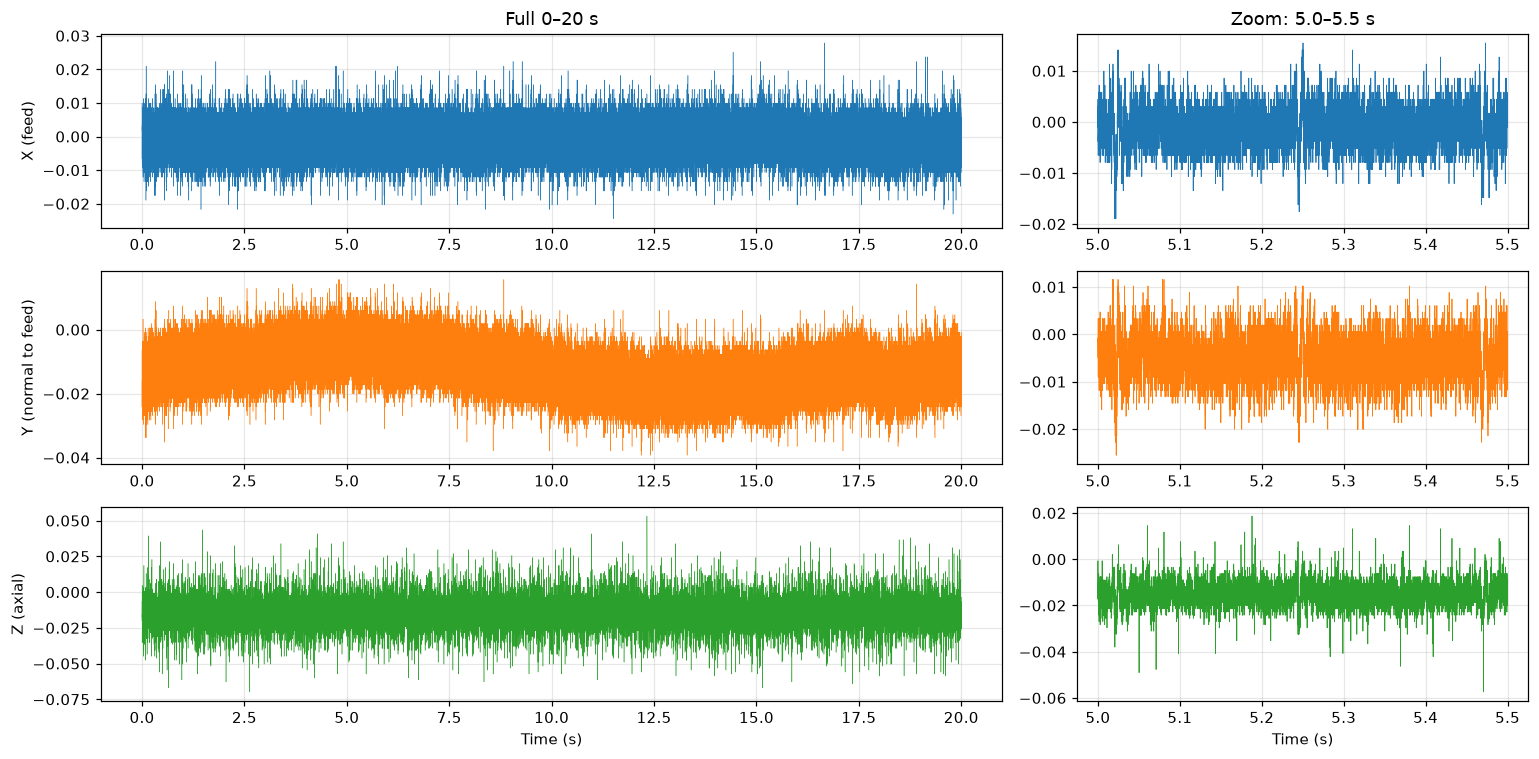

In [2]:
fig, ax = plt.subplots(3, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [2, 1]})
z0, z1 = int(5.0*FS), int(5.5*FS)
for i in range(3):
    ax[i,0].plot(t, x[:,i], lw=0.3, color=COL[i]); ax[i,0].set_ylabel(AX[i])
    ax[i,1].plot(t[z0:z1], x[z0:z1,i], lw=0.5, color=COL[i])
ax[0,0].set_title('Full 0–20 s'); ax[0,1].set_title('Zoom: 5.0–5.5 s')
ax[2,0].set_xlabel('Time (s)'); ax[2,1].set_xlabel('Time (s)')
plt.tight_layout(); plt.savefig(FIG/'01_noise_time.png'); plt.show()

## 2. Basic statistics and ADC resolution

The recorded values only take a small set of discrete levels, so the ADC step size matters: the noise is only a few steps wide.

In [3]:
rows = []
for i in range(3):
    v = x[:,i]; lv = np.unique(v); step = np.median(np.diff(lv))
    rows.append((AX[i], v.mean(), v.std(), v.min(), v.max(), stats.skew(v), stats.kurtosis(v), len(lv), step, v.std()/step))
print(f"{'axis':20s}{'mean':>10s}{'std':>10s}{'min':>10s}{'max':>10s}{'skew':>8s}{'ex.kurt':>9s}{'levels':>8s}{'ADC step':>11s}{'std/step':>10s}")
for r in rows:
    print(f"{r[0]:20s}{r[1]:10.5f}{r[2]:10.5f}{r[3]:10.4f}{r[4]:10.4f}{r[5]:8.3f}{r[6]:9.3f}{r[7]:8d}{r[8]:11.6f}{r[9]:10.2f}")
STEP = float(np.median([r[8] for r in rows]))
print('\nGaussian reference: skew = 0, excess kurtosis = 0')
print('correlation between axes:\n', np.round(np.corrcoef(x.T), 3))

axis                      mean       std       min       max    skew  ex.kurt  levels   ADC step  std/step
X (feed)              -0.00097   0.00393   -0.0245    0.0278   0.053    0.694      38   0.001377      2.86
Y (normal to feed)    -0.01245   0.00619   -0.0393    0.0157   0.034   -0.190      41   0.001375      4.50
Z (axial)             -0.01506   0.00498   -0.0698    0.0532   0.146    5.090      81   0.001382      3.61

Gaussian reference: skew = 0, excess kurtosis = 0
correlation between axes:
 [[1.    0.127 0.299]
 [0.127 1.    0.138]
 [0.299 0.138 1.   ]]


## 3. Is it Gaussian?

Left: histogram (one bar per ADC level) against the Gaussian with the same mean and standard deviation, on a log scale so the tails are visible. Right: Q-Q plot; points on the dashed line mean Gaussian.

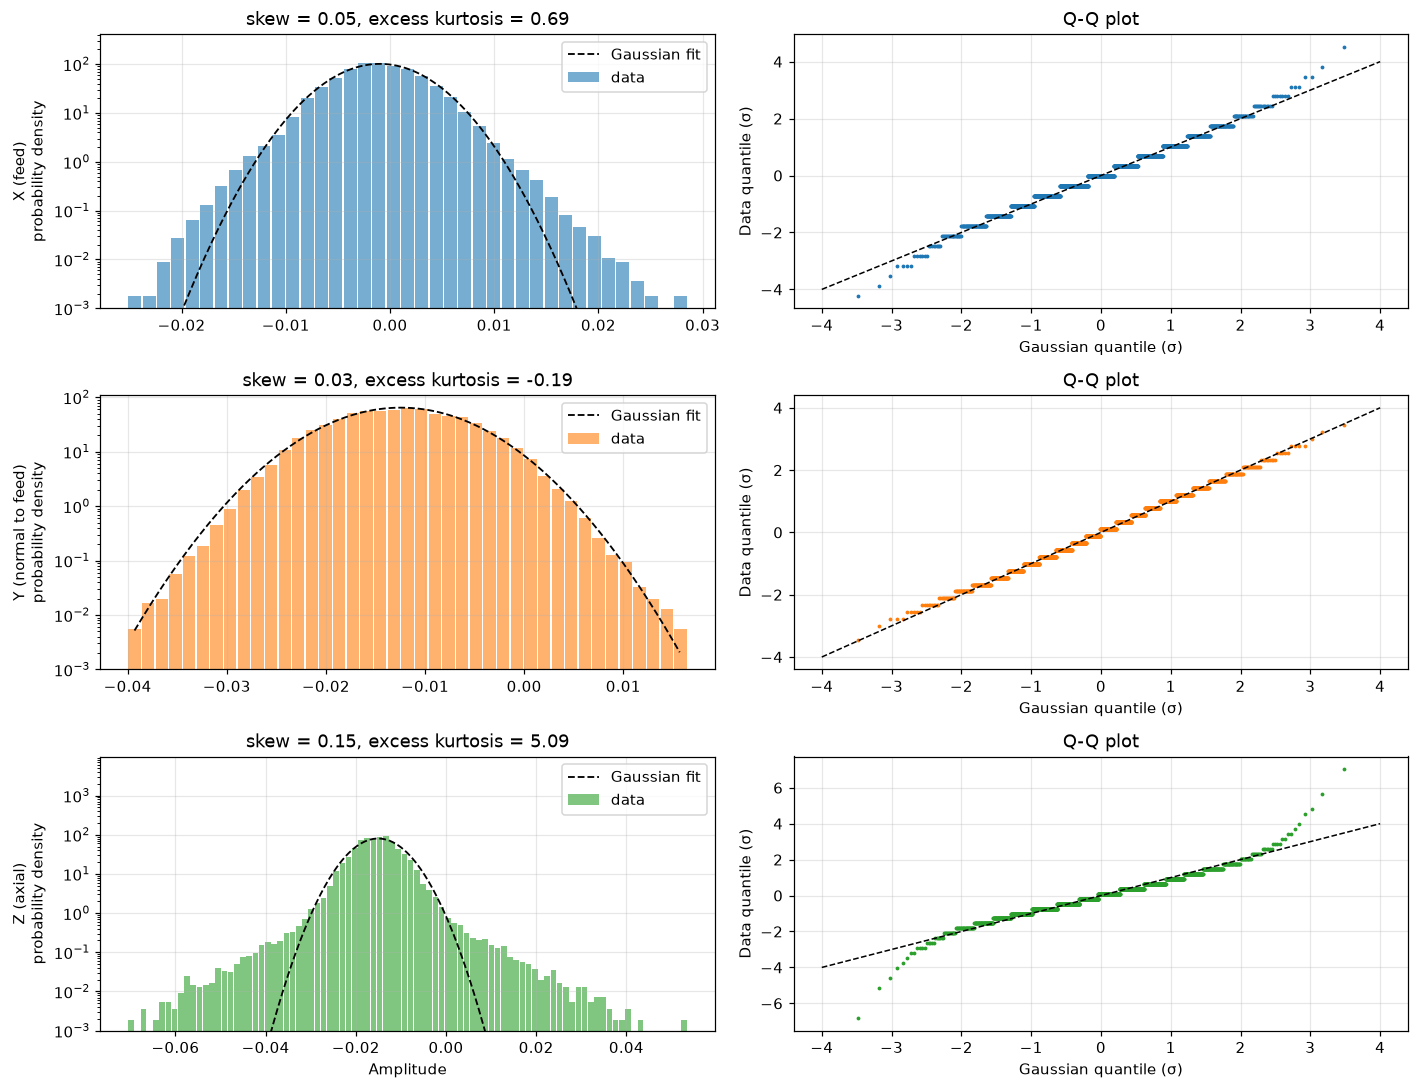

In [4]:
fig, ax = plt.subplots(3, 2, figsize=(13, 10))
for i in range(3):
    v = x[:,i]; mu, sd = v.mean(), v.std()
    lv, cnt = np.unique(np.round((v - v.min())/STEP).astype(int), return_counts=True)
    centres = v.min() + lv*STEP
    ax[i,0].bar(centres, cnt/cnt.sum()/STEP, width=STEP*0.9, color=COL[i], alpha=0.6, label='data')
    g = np.linspace(v.min(), v.max(), 400)
    ax[i,0].plot(g, stats.norm.pdf(g, mu, sd), 'k--', lw=1.2, label='Gaussian fit')
    ax[i,0].set_yscale('log'); ax[i,0].set_ylim(1e-3, None)
    ax[i,0].set_ylabel(AX[i] + '\nprobability density'); ax[i,0].legend()
    ax[i,0].set_title(f'skew = {stats.skew(v):.2f}, excess kurtosis = {stats.kurtosis(v):.2f}')
    p = (np.arange(1, 2001) - 0.5)/2000
    q = np.quantile(v, p); th = stats.norm.ppf(p)
    ax[i,1].plot(th, (q - mu)/sd, '.', ms=3, color=COL[i])
    ax[i,1].plot([-4,4], [-4,4], 'k--', lw=1)
    ax[i,1].set_xlabel('Gaussian quantile (σ)'); ax[i,1].set_ylabel('Data quantile (σ)'); ax[i,1].set_title('Q-Q plot')
ax[2,0].set_xlabel('Amplitude')
plt.tight_layout(); plt.savefig(FIG/'01_noise_gaussianity.png'); plt.show()

## 4. Is it white? Power spectral density

A flat PSD means white noise. Narrow spikes are periodic sources. Spindle rotation is 20,000/60 = 333.3 Hz.

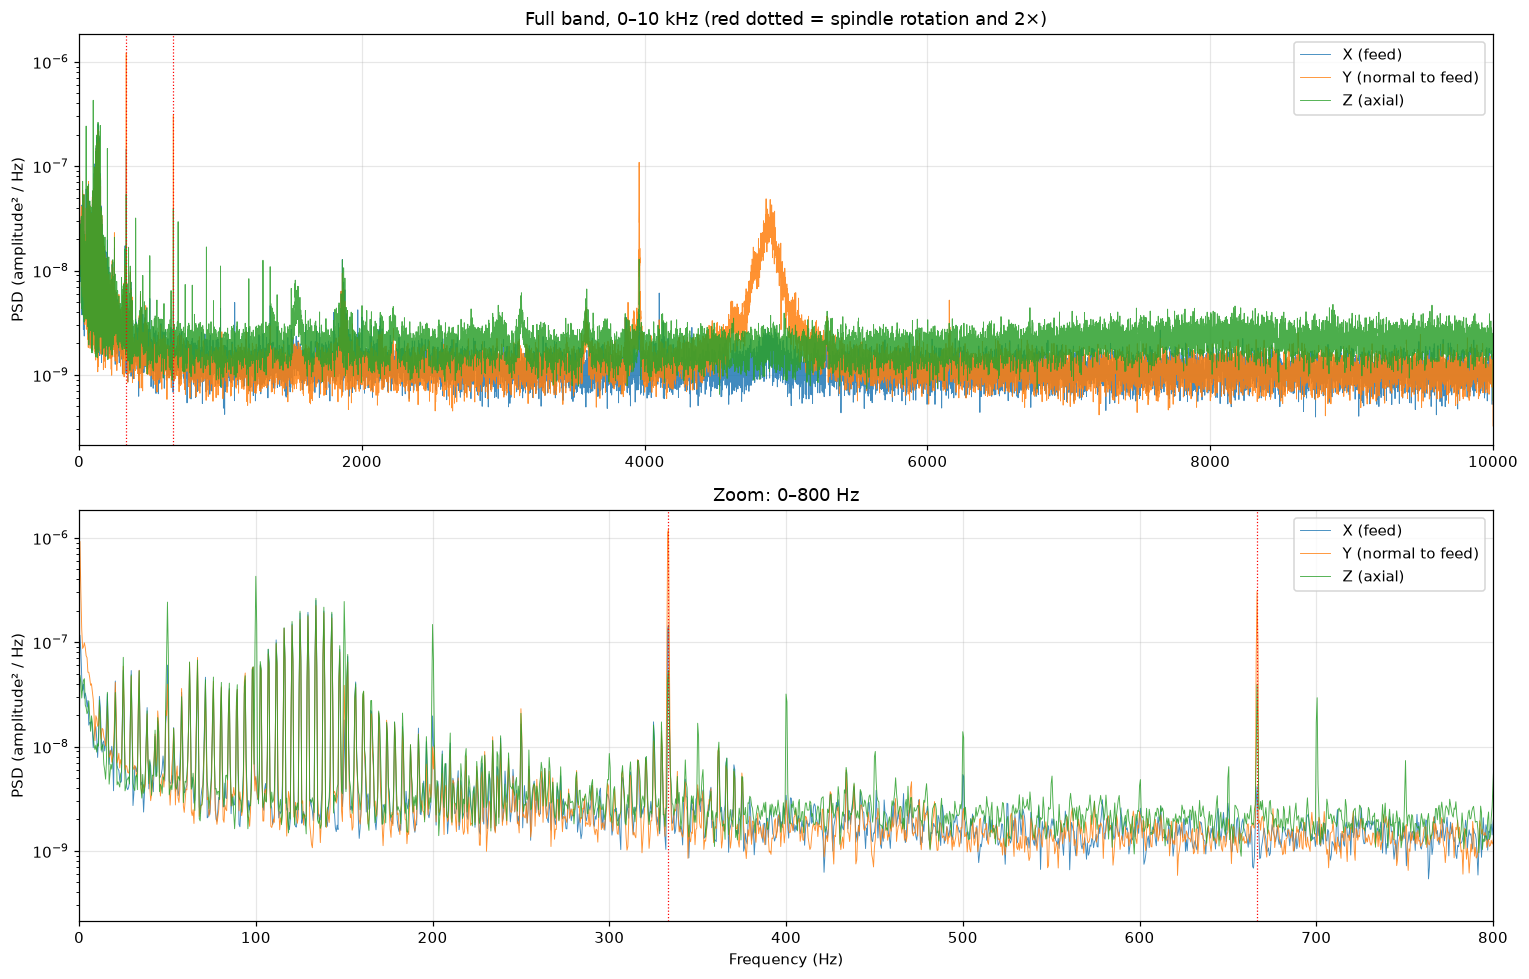

share of total power per band (%)
     band (Hz)       X       Y       Z
     0-20          2.9     5.7     1.4
    20-100         5.8     4.0     4.5
   100-200        11.5     7.4     9.4
   200-500         6.3     8.7     4.8
   500-1000        4.7     4.0     4.4
  1000-2000        8.7     5.5     9.0
  2000-4000       15.7    12.6    16.3
  4000-6000       15.7    32.2    14.8
  6000-8000       14.5    10.1    17.2
  8000-10000      14.3     9.8    18.3


In [5]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
psd = {}
for i in range(3):
    f, P = signal.welch(x[:,i] - x[:,i].mean(), FS, nperseg=2*FS, noverlap=FS)
    psd[i] = (f, P)
    for a in ax: a.semilogy(f, P, lw=0.6, color=COL[i], label=AX[i], alpha=0.85)
for a in ax:
    for k in (1, 2):
        a.axvline(k*RPM/60, color='r', ls=':', lw=0.8)
    a.set_ylabel('PSD (amplitude² / Hz)'); a.legend(loc='upper right')
ax[0].set_xlim(0, FS/2); ax[0].set_title('Full band, 0–10 kHz (red dotted = spindle rotation and 2×)')
ax[1].set_xlim(0, 800); ax[1].set_title('Zoom: 0–800 Hz'); ax[1].set_xlabel('Frequency (Hz)')
plt.tight_layout(); plt.savefig(FIG/'01_noise_psd.png'); plt.show()

edges = [0, 20, 100, 200, 500, 1000, 2000, 4000, 6000, 8000, 10000]
print('share of total power per band (%)')
print(f"{'band (Hz)':>14s}" + ''.join(f'{a[:1]:>8s}' for a in AX))
for a, b in zip(edges[:-1], edges[1:]):
    print(f'{a:6d}-{b:<6d} ' + ''.join(f"{100*psd[i][1][(psd[i][0]>=a)&(psd[i][0]<b)].sum()/psd[i][1].sum():8.1f}" for i in range(3)))

In [6]:
# narrow peaks standing well above the local noise floor
from scipy.ndimage import median_filter
for i in range(3):
    f, P = psd[i]; bg = median_filter(P, 201); r = P/bg
    pk, _ = signal.find_peaks(r, height=30, distance=3)
    floor = np.median(P[f > 1000])
    df = f[1] - f[0]
    print(f'{AX[i]:20s} flat floor above 1 kHz = {floor:.2e};  flat (white) floor share of total variance = {100*floor*(FS/2)/(P.sum()*df):.0f}%')
    print('    peaks (Hz, times above local floor):', [(float(f[j]), int(r[j])) for j in pk])

X (feed)             flat floor above 1 kHz = 1.14e-09;  flat (white) floor share of total variance = 74%
    peaks (Hz, times above local floor): [(116.0, 37), (120.5, 42), (125.0, 54), (129.5, 54), (134.0, 72), (138.5, 60), (143.0, 59), (333.5, 63)]
Y (normal to feed)   flat floor above 1 kHz = 1.19e-09;  flat (white) floor share of total variance = 53%
    peaks (Hz, times above local floor): [(0.5, 80), (116.0, 38), (120.5, 41), (125.0, 46), (129.5, 50), (134.0, 65), (138.5, 60), (143.0, 54), (333.5, 629), (666.5, 225), (3961.0, 46)]
Z (axial)            flat floor above 1 kHz = 1.99e-09;  flat (white) floor share of total variance = 80%
    peaks (Hz, times above local floor): [(50.0, 42), (100.0, 107), (116.0, 36), (120.5, 41), (125.0, 52), (129.5, 49), (134.0, 72), (138.5, 59), (143.0, 53), (150.0, 69), (200.0, 39)]


## 5. Is it steady over time?

Mean and standard deviation in 1 s blocks. Flat lines mean the noise is stationary.

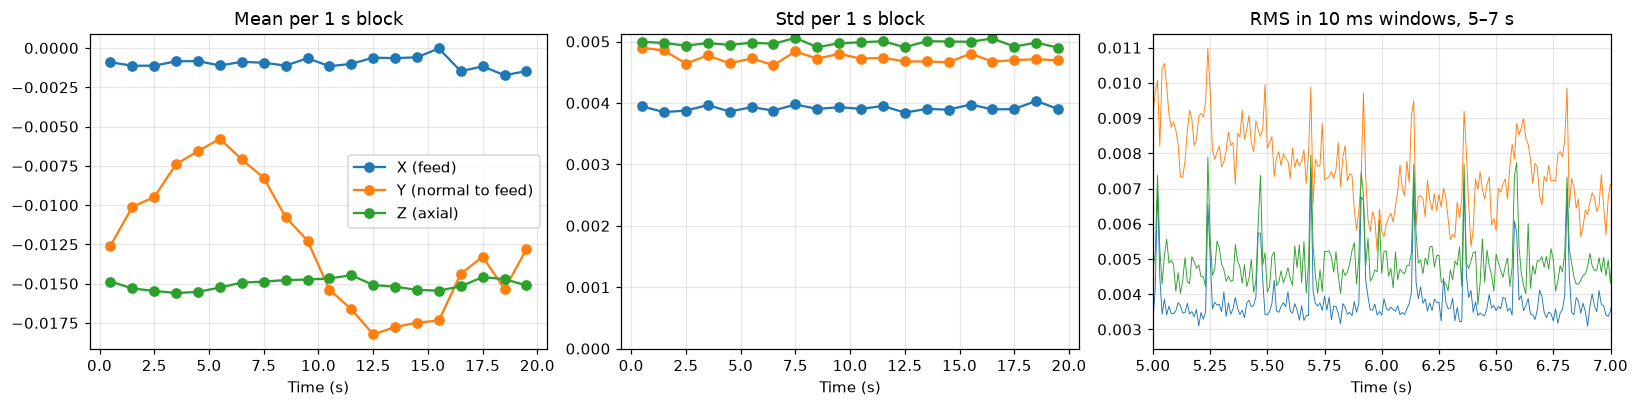

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sec = np.arange(20) + 0.5
for i in range(3):
    b = x[:,i].reshape(20, -1)
    ax[0].plot(sec, b.mean(1), 'o-', color=COL[i], label=AX[i])
    ax[1].plot(sec, b.std(1), 'o-', color=COL[i], label=AX[i])
    w = 200
    r = np.sqrt(((x[:,i]-x[:,i].mean())[:n//w*w].reshape(-1, w)**2).mean(1))
    ax[2].plot(np.arange(len(r))*w/FS, r, lw=0.6, color=COL[i])
ax[0].set_title('Mean per 1 s block'); ax[1].set_title('Std per 1 s block'); ax[2].set_title('RMS in 10 ms windows, 5–7 s')
ax[2].set_xlim(5, 7); ax[1].set_ylim(0, None); ax[0].legend()
for a in ax: a.set_xlabel('Time (s)')
plt.tight_layout(); plt.savefig(FIG/'01_noise_stationarity.png'); plt.show()

## 6. Autocorrelation

White noise has zero autocorrelation at every lag except 0. Structure here means the samples are not independent.

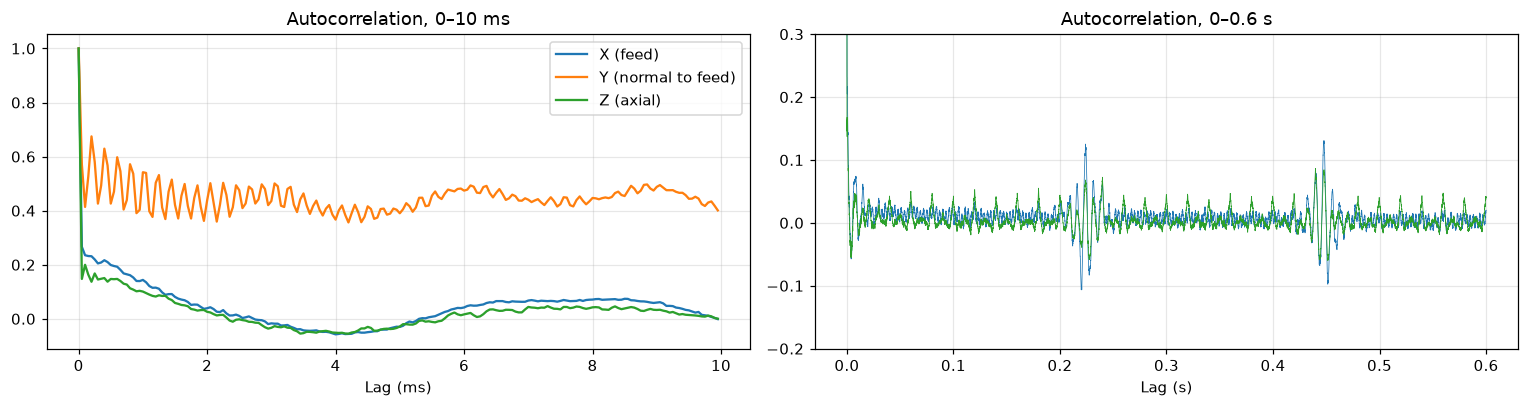

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for i in range(3):
    v = x[:,i] - x[:,i].mean()
    F = np.fft.rfft(v, 2*len(v)); ac = np.fft.irfft(np.abs(F)**2)[:len(v)]; ac /= ac[0]
    ax[0].plot(np.arange(200)/FS*1000, ac[:200], color=COL[i], label=AX[i])
    ax[1].plot(np.arange(int(0.6*FS))/FS, ac[:int(0.6*FS)], lw=0.5, color=COL[i])
ax[0].set_xlabel('Lag (ms)'); ax[0].set_title('Autocorrelation, 0–10 ms'); ax[0].legend()
ax[1].set_xlabel('Lag (s)'); ax[1].set_title('Autocorrelation, 0–0.6 s'); ax[1].set_ylim(-0.2, 0.3)
plt.tight_layout(); plt.savefig(FIG/'01_noise_autocorr.png'); plt.show()

## 7. Findings (20k rpm, 0–20 s, spindle on, no cutting)

**Gaussian?**
- **X (feed):** close to Gaussian in the middle, with slightly heavy tails (excess kurtosis 0.69).
- **Y (normal to feed):** close to Gaussian (excess kurtosis −0.19). The slight flattening comes from the slow drift in its mean.
- **Z (axial):** not Gaussian. The core is Gaussian but there are frequent large spikes, giving heavy tails (excess kurtosis 5.1, values out to ±7σ).

**White?** No. It is a flat floor plus several periodic sources.
- Above about 1 kHz the floor is flat (white). It carries roughly 74 % of the variance in X, 53 % in Y and 80 % in Z.
- Below about 500 Hz the floor rises (more low-frequency content).
- **Spindle rotation:** sharp lines at 333.5 Hz and 667 Hz, strongest in Y. This confirms 20,000 rpm.
- **4.5 Hz comb:** a set of lines spaced 4.5 Hz apart, strongest at 110–150 Hz, on all three axes. In time this is a short burst repeating every 0.22 s (visible in the zoomed trace and the 10 ms RMS plot). Source not identified.
- **Mains:** 50 Hz and its multiples (100, 150, 200 Hz ...) on Z.
- **Y only:** a broad hump around 4.9 kHz holding about a third of Y's power, and a narrow line at 3961 Hz. Source not identified; a structural or mounting resonance is a candidate.

**Steady over time?**
- The standard deviation is constant over the 20 s on all axes.
- The mean of Y drifts slowly (about −0.006 to −0.018). X and Z means are steady.

**Measurement resolution**
- The ADC step is 0.00138. The noise is only 3–4.5 steps wide, so the no-cutting signal is coarsely resolved. Quantisation itself adds only about 1 % of the variance.

**Other**
- The three axes are only weakly correlated (0.13–0.30), so the noise is mostly independent per axis.

**What this means for denoising**
- Remove the mean and slow drift (high-pass at a few Hz), mainly for Y.
- The flat floor cannot be filtered out without also removing signal in the same band; it sets the minimum detectable level.
- The narrow lines (mains, 4.5 Hz comb) can be notched or subtracted. Spindle harmonics should be kept or handled separately, because cutting forces appear at the same frequencies.
- Z needs spike-robust handling (median or clipping), or it should be used with care.
- Units are as recorded in the file; the conversion to g has not been applied.